# Splitting Intensity for the Southwest Pacific: Variable Combination Exploration

In [ ]:
import matplotlib.pyplot as plt 
import matplotlib.gridspec as gridspec
import numpy as np 
import pandas as pd 
import scipy.optimize as sci 
import scipy.stats as stats
import sys
# from pathlib import Path
import traceback
# import time
# import datetime
# sys.path.append("/work/gcl3/BR/nicolasv03/senior_thesis/data/maps/")
# /work/gcl3/BR/nicolasv03/senior_thesis/data/maps/plot_great_circle.py
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pyproj import Geod
from obspy import read
import splitwavepy as sw 
from obspy.geodetics import gps2dist_azimuth

from support import plot_great_circle_ray_path, plot_trace_final, envelopes


In [ ]:
### IMPORT DATA ### 
# --------------- filepath names of data being used ---------------- 
dataType    = 'complete'
networkName = 'AU'
stationName = 'australia'
freqType = 'normal'
manual = False
stat = 'BBOO' # if only looking at a single


dir_stations  = '../data/'+dataType+'/'+stationName+'/'+networkName+'_stations_info.txt'
stations_df  = pd.read_csv(dir_stations,sep='|',header=0)
output_dir      = '../data/'+dataType+'/'+stationName+'/'+networkName

# -------- retrieving measurements and refining which results to use ---------
raw_eventdata = pd.read_csv('/work/gcl3/BR/nicolasv03/senior_thesis/data/'+dataType+'/'+stationName+'/'+networkName+'_measured_events_'+freqType+'_sep28.txt',sep='|')
# eventData = pd.read_csv('/work/gcl3/BR/nicolasv03/senior_thesis/data/'+dataType+'/'+stationName+'/'+networkName+'_events_measurements_apr21.txt',sep='|')
station_names = stations_df['Station']

# -------- Wolf's measurements
fullwolf = pd.read_csv('/work/gcl3/BR/nicolasv03/senior_thesis/measurements/SKS_global_SI.txt',sep=r"\s+",engine="python") #,names=colnames,quotechar="'",)


# output file for saved measurements
columns = ['Station','Latitude','Longitude','phi', 'dt'] 
saved_df = pd.DataFrame(columns=columns)



In [ ]:

eventData = raw_eventdata.copy()
# --------- criteria for measurements to be used -----------

ravel   = False     # False: 0 - 180 azimuth range, True: 0 - 360 azimuth range
single  = True      # single layer or double layer of anisotropy 

snr_threshold = 4           # Signal / Noise Filter (Restivo & Helffrich 1999)
snrbefore_threshold = 1.0   # Signal Noise Ratio before phase window 
snrafter_threshold = 1.0    # Signal Noise Ratio after phase window 
sta_lta_threshold = 4      # STA/LTA minimum (phase prominence)
ellipticity_threshold = 40  # ellipticity of particle motion (needs to be worked on)
mag_threshold = 7.0         # eq magnitude maximum (larger eq's source mechanisms contaminate signal)
sierrmax = 0.5           # SI error maximum 
s_depth = 400               # eq depth to be marked as 's_depth'
sample_rate = 1             # sample rate of waveforms, needed to rescale SI? ask jonathan about this
# dataset truncation based on criteria

# eventData = eventData[eventData['delta_travel'] < 20]
# # eventData = eventData[eventData['beta']<10]
# eventData = eventData[eventData['evincident']<25]
eventData = eventData[eventData['evepic']<60]
# eventData = eventData[eventData['evpiercedepth']>=1500]

# eventData = eventData[eventData['evdp']>500]

# eventData = eventData[eventData['snr'] > snr_threshold]
# eventData = eventData[eventData['snrbefore'] > snrbefore_threshold]
# eventData = eventData[eventData['snrafter'] > snrafter_threshold]
# eventData = eventData[eventData['sta_lta'] > sta_lta_threshold]
# eventData = eventData[eventData['evmg'] < mag_threshold]
# eventData = eventData[eventData['ellipticity'] > ellipticity_threshold]

# calculate SI errors and also trunate 

eventData.loc[:, 'SI_calc_error'] = abs(eventData['wiggleSI_calc'] - eventData['wiggleSIlow_calc'])
eventData = eventData[eventData['SI_calc_error'] < sierrmax]
eventData = eventData[eventData['SI_calc_error'] != 0]



if ravel: 
    eventData['calcbaz'] = eventData['calcbaz'] % 180
    degs = np.arange(0,180,1)
else:
    degs = np.arange(0,360,1)
rads = np.radians(degs)

# ---------- measurement binning criteria ----------
sks_weight       = 1
s_weight         = 1
s_depth_weight   = 1
s_shallow_weight = 1
bin_width        = 5   # width of bin in degrees
bin_minimum      = 2   # minimum number of measurements within a bin to calculate a confidence interval
array            = np.arange(0, 360, bin_width)      # designed to be used for non-raveled results

print(len(eventData))

In [ ]:
def single_station_SI(stat):
    try:
        eventdata = eventData[eventData['evstation']==stat].copy()
        eventdata = eventdata.drop_duplicates(subset=['evtime','evphase'])
        print(f"Filtered measurement catalog length for {stat}:", len(eventdata))

        wolf = fullwolf[fullwolf['station_code']==stat]
        wolf["backaz"] = wolf.apply(
            lambda row: gps2dist_azimuth(
                row["station_lat"], row["station_lon"],
                row["event_lat"], row["event_lon"]
            )[2],  # index 2 = back azimuth
            axis=1
        )


        if len(eventdata) == 0:
            return print("ermmm it did not work")

        # arrange each measurement to be within a bin called 'chunk'
        eventdata = eventdata.sort_values(by='calcbaz', ascending=True)
        eventdata['chunk'] = np.digitize(eventdata['calcbaz'], array, right=True) 
        eventdata['pass'] = None

    #     df_unique = df.drop_duplicates(
    # subset=["time", "phase", "net", "sta", "filepath"]


        # eventdata.to_csv(output_dir+'_listofmeasurementssep19.txt', sep='|', index=False)

        ################## plot waveforms final #########   
        # Frequency selection
        if freqType == 'low':
            freqmin, freqmax = 0.04, 0.125
        elif freqType == 'medium':
            freqmin, freqmax = 0.125, 0.2
        elif freqType =='high':
            freqmin, freqmax = 0.2, 1
        elif freqType == 'normal':
            freqmin, freqmax = 0.01, 0.125

        if manual:
            for i in range(0,len(eventdata)):
                row = eventdata.iloc[i]
                wf = read(row['waveform_path'])
                print(row['evtime'])

                # Filtering
                wf.detrend('demean')
                wf.detrend('linear')
                wf.filter("bandpass", freqmin=freqmin, freqmax=freqmax)

                north = wf.select(component="N", channel='BH*')[0].data
                east  = wf.select(component="E", channel='BH*')[0].data
                sample_interval = wf[0].stats.delta

                if len(north) % 2 == 0: north = north[:-1]
                if len(east) % 2 == 0: east = east[:-1]

                evwindowstart = int(row['windowstart'] / sample_interval)
                evwindowend = int(row['windowend'] / sample_interval)
                # print(evwindowstart,evwindowend)
                pair = sw.Pair(north, east, delta=sample_interval)

                a,b,env,c,d  = envelopes(pair,row['evbaz'],row['calcbaz'],evwindowstart,evwindowend)
                kwargs = {'title': f"Event: {row['evtime']} Phase: {row['evphase']} Depth: {row['evdp']} Mag: {row['evmg']} Epic: {round(row['evepic'],1)}"}
                plot_trace_final(pair,row['evbaz'],row['calcbaz'],evwindowstart,evwindowend,env,**kwargs)
                plt.show()    

            choice = input("Save result? (y/n): ").strip().lower()

            if choice == "y":
                eventdata['pass'].iloc[i] = 1
                print('measurement saved')
                # Mark only this row with 1
                # data[i, 1] = 1
            else:
                eventdata['pass'].iloc[i] = 0 
                print("measurement not saved.")


        # eventdata = eventdata[eventdata['pass']==1]
        # print(f"this is the length{len(eventdata)}")

        #################################################

        # binned results per each station 
        binned_sks_results          = np.zeros((len(array), 6))
        binned_s_results            = np.zeros((len(array), 6))
        binned_s_depth_results      = np.zeros((len(array), 6))
        binned_s_shallow_results    = np.zeros((len(array), 6))

        # loop to calculate mean/median and confidence interval per phase category per bin

        for chunk in range(0,len(array)):
            bin_eventdata = eventdata[eventdata['chunk'] == chunk + 1]
            # si_values_sks = bin_eventdata['wiggleSI_calc'] # only for using all measurements for bins lol
            si_values_sks = bin_eventdata[bin_eventdata['evphase'] == 'SKS']['wiggleSI_calc']
            si_values_s   = bin_eventdata[(bin_eventdata['evphase'] == 'S')]['wiggleSI_calc']
            si_values_s_depth   = bin_eventdata[(bin_eventdata['evphase'] == 'S')
                                                &(bin_eventdata['evdp'] >= s_depth)]['wiggleSI_calc']
            si_values_s_shallow = bin_eventdata[(bin_eventdata['evphase'] == 'S')
                                                &(bin_eventdata['evdp'] < s_depth)]['wiggleSI_calc']

            si_cases = [
                        (si_values_sks,         binned_sks_results,         sks_weight,        1),
                        (si_values_s,           binned_s_results,           s_weight,          2),
                        (si_values_s_depth,     binned_s_depth_results,     s_depth_weight,    3),
                        (si_values_s_shallow,   binned_s_shallow_results,   s_shallow_weight,  4)
                        ]
            
            # confidence interval per phase within a bin 
            for si_values_in_bin, results, phase_weight, name in si_cases:
                n = len(si_values_in_bin)

                if n <= bin_minimum:
                    results[chunk, :] = chunk, 0, 0, 0, 0, 0
                    continue

                mean = np.mean(si_values_in_bin)  # or np.mean
                std = np.std(si_values_in_bin, ddof=1)
                conf = 0.95

                # t-critical value
                t_crit = stats.t.ppf((1 + conf) / 2, df=n - 1)

                # Margin of error
                margin = t_crit * (std / np.sqrt(n))

                ci_lower = mean - margin
                ci_upper = mean + margin

                weight = margin / phase_weight

                results[chunk, :] = chunk,mean,weight,array[chunk] + bin_width/2,margin,name
            
        # remove all empty bins 
        binned_s_results = binned_s_results[binned_s_results[:,2] != 0, :]
        binned_sks_results = binned_sks_results[binned_sks_results[:,2] != 0, :]
        binned_s_depth_results = binned_s_depth_results[binned_s_depth_results[:,2] != 0, :]
        binned_s_shallow_results = binned_s_shallow_results[binned_s_shallow_results[:,2] != 0, :]

        # combine all results into one array 
        # binned_results  = np.vstack((binned_s_results, binned_sks_results,binned_s_depth_results,binned_s_shallow_results))
        # binned_results  = np.vstack((binned_sks_results,binned_s_depth_results,binned_s_shallow_results))
        binned  = np.vstack((binned_sks_results,binned_s_results))
        binned_results = pd.DataFrame(binned,columns=['chunk','mean','weight','azimuth','margin','name'])
        binned_results = binned_results[binned_results['margin']<= 1]
        # binned_results = binned_results[binned_results[] < ]
        # print(binned_results)

        # sys.exit()

        # # SI function for nonlinear least squares regression
        # def SI_function(baz,fast,lag):
        #     SI = lag * 2 * np.sin(np.deg2rad(baz-fast)) * np.cos(np.deg2rad(baz-fast))
        #     return SI
        # bounds = ([-360, 0], [360,4])

        # sine_fit = sci.curve_fit(SI_function,binned_results['azimuth'],binned_results['mean'],sigma=binned_results['weight'],bounds=bounds,full_output=True,nan_policy='omit') #,p0=p0)
        # params,cov,fitdata,trash1,trash2 = sine_fit
        # phi,dt = params[0],params[1]

        def SI_function(baz_incident,fast,lag,tilt):
            baz,incident = baz_incident
            SI = lag * ((np.cos(np.deg2rad(tilt))**2 * np.sin(2*np.deg2rad(baz-fast))) 
                            + (np.sin(2*np.deg2rad(tilt)) * np.sin(np.deg2rad(baz-fast)) * np.tan(np.deg2rad(incident))))
            return SI
        bounds = ([-360, 0, 0], [360, 4, 45])

        sine_fit = sci.curve_fit(SI_function,(binned_results['azimuth'],np.full_like(binned_results['azimuth'],20)),binned_results['mean'],sigma=binned_results['weight'],bounds=bounds,full_output=True,nan_policy='omit') #,p0=p0)
        params,cov,fitdata,trash1,trash2 = sine_fit
        phi,dt,tilt = params[0],params[1],params[2]

        # sine_fit = sci.curve_fit(SI_function,baz_and_incident,binned_results[:,1],sigma=binned_results[:,2],bounds=bounds,full_output=True,nan_policy='omit') #,p0=p0)
        #     # sine_fit = sci.curve_fit(SI_function,baz_and_incident,eventdata['wiggleSI_calc'],sigma=inv_weight,bounds=bounds,full_output=True) #,p0=p0)
        #     params,cov,fitdata,trash1,trash2 = sine_fit
        #     phi,dt,tilt = params[0],params[1],params[2]


        

        # if dt < 0.5:
        #     continue


        # plotting graph with all indivudual measurements and SI errors
        # Make a 2x3 grid
        fig = plt.figure(figsize=(20, 16))
        fig.supylabel("Splitting Intensity")
        gs = gridspec.GridSpec(4, 8, figure=fig)
        ax1 = fig.add_subplot(gs[0:2, :4])  # top-left
        ax2 = fig.add_subplot(gs[2:4, :4])  # bottom-left
        # ax3 = fig.add_subplot(gs[:, 1:])  # spans both rows, columns 1 and 2
        # plt.figure(figsize=(20,10))
        # plt.subplot(2,2,1)
        # plt.ylim(-2,2)
        # plt.title(f"{station_name} SI measurements for SKS and S, phi={round(phi,3)} dt={round(dt,3)} ")
        # plt.legend()
        ax1.set_title(f"{stat} SI measurements for SKS and S, phi={round(phi,3)} dt={round(dt,3)*sample_rate}, tilt={round(tilt,3)} ")
        ax1.legend()
        # ax1.legend(loc='upper right', bbox_to_anchor=(0.5, -0.05),
        #   fancybox=True, shadow=True, ncol=3, fontsize = 5)
        ax1.set_ylim(-3,3)
        sks_tick = 0 
        s_tick = 0
        s_depth_tick = 0 
        s_shallow_tick = 0 

        for i in range(0,len(eventdata)):
            if eventdata['evphase'].iloc[i] == 'SKS':
                label = 'SKS phase' if sks_tick == 0 else None
                sks_tick += 1
                ax1.plot(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],'.',color='blue',alpha=0.5,label=label)
                ax1.errorbar(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='blue',barsabove=True,alpha=0.5)
                # print('sks_tick:  ', sks_tick)

        
            if eventdata['evphase'].iloc[i] == 'S': 
                s_tick += 1 
                if eventdata['evdp'].iloc[i] >= s_depth:
                    label = 'S deep phase' if s_depth_tick == 0 else None
                    s_depth_tick += 1
                    ax1.plot(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],'.',color='green',alpha=0.5,label=label)
                    ax1.errorbar(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='green',barsabove=True,alpha=0.5)
                    # print('s_depth_tick:  ', s_depth_tick)

                else:
                    label = 'S shallow phase' if s_shallow_tick == 0 else None
                    s_shallow_tick += 1
                    ax1.plot(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],'.',color='red',alpha=0.5,label=label)
                    ax1.errorbar(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='red',barsabove=True,alpha=0.5)
                    # print('s_tick:  ', s_shallow_tick)

        k = 1        
        # ax1.plot(degs , k * SI_function(degs, *params),color='black',linewidth=5)          #parameters calculated from binned back azimuths 

        incs = np.full_like(degs,30)
        vars = np.vstack((degs,incs))
        ax1.plot(degs , SI_function(vars, *params),color='black',linewidth=5)   
        # for i in range(0,len(eventdata)):
        #     if eventdata['evphase'].iloc[i] == 'SKS':
        #         label = 'SKS phase' if sks_tick == 0 else None
        #         sks_tick += 1
        #         ax2.plot(eventdata['evbaz'].iloc[i],eventdata['wiggleSI_act'].iloc[i],'.',color='blue',alpha=0.5,label=label)
        #         ax2.errorbar(eventdata['evbaz'].iloc[i],eventdata['wiggleSI_act'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='blue',barsabove=True,alpha=0.5)
        #         print('sks_tick:  ', sks_tick)

        
        #     if eventdata['evphase'].iloc[i] == 'S': 
        #         s_tick += 1 
        #         if eventdata['evdp'].iloc[i] >= s_depth:
        #             label = 'S deep phase' if s_depth_tick == 0 else None
        #             s_depth_tick += 1
        #             ax2.plot(eventdata['evbaz'].iloc[i],eventdata['wiggleSI_act'].iloc[i],'.',color='green',alpha=0.5,label=label)
        #             ax2.errorbar(eventdata['evbaz'].iloc[i],eventdata['wiggleSI_act'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='green',barsabove=True,alpha=0.5)
        #             print('s_depth_tick:  ', s_depth_tick)

        #         else:
        #             label = 'S shallow phase' if s_shallow_tick == 0 else None
        #             s_shallow_tick += 1
        #             ax2.plot(eventdata['evbaz'].iloc[i],eventdata['wiggleSI_act'].iloc[i],'.',color='red',alpha=0.5,label=label)
        #             ax2.errorbar(eventdata['evbaz'].iloc[i],eventdata['wiggleSI_act'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='red',barsabove=True,alpha=0.5)
        #             print('s_tick:  ', s_shallow_tick)


        # for i in range(0,len(binned_results)):
        #     if binned_results[i,5] == 1:
        #         ax2.plot(binned_results[i,3],binned_results[i,1],'o',color='blue')
        #         ax2.errorbar(binned_results[i,3],binned_results[i,1],yerr=binned_results[i,4],color='blue')

        #     if binned_results[i,5] == 2:
        #         ax2.plot(binned_results[i,3],binned_results[i,1],'o',color='red')
        #         ax2.errorbar(binned_results[i,3],binned_results[i,1],yerr=binned_results[i,4],color='red')

        #     if binned_results[i,5] == 3:
        #         ax2.plot(binned_results[i,3],binned_results[i,1],'o',color='green')
        #         ax2.errorbar(binned_results[i,3],binned_results[i,1],yerr=binned_results[i,4],color='orange')

        #     if binned_results[i,5] == 4:
        #         ax2.plot(binned_results[i,3],binned_results[i,1],'o',color='orange')
        #         ax2.errorbar(binned_results[i,3],binned_results[i,1],yerr=binned_results[i,4],color='green')

        for i, row in binned_results.iterrows():
            if row["name"] == 1:
                ax2.plot(row["azimuth"], row["mean"], 'o', color='blue')
                ax2.errorbar(row["azimuth"], row["mean"], yerr=row["margin"], color='blue')

            elif row["name"] == 2:
                ax2.plot(row["azimuth"], row["mean"], 'o', color='red')
                ax2.errorbar(row["azimuth"], row["mean"], yerr=row["margin"], color='red')

            elif row["name"] == 3:
                ax2.plot(row["azimuth"], row["mean"], 'o', color='green')
                ax2.errorbar(row["azimuth"], row["mean"], yerr=row["margin"], color='orange')

            elif row["name"] == 4:
                ax2.plot(row["azimuth"], row["mean"], 'o', color='orange')
                ax2.errorbar(row["azimuth"], row["mean"], yerr=row["margin"], color='green')

        ax2.plot(wolf['backaz'],wolf['SI'],'o',color='pink')
        # ax2.errorbar(wolf['backaz'],wolf['SI'],ls='o',yerr=wolf['SI_plus_err'],color='pink')
        # ax2.plot(degs , k* SI_function(degs, *params),color='black',linewidth=5)          #parameters calculated from binned back azimuths 
        incs = np.full_like(degs,30)
        vars = np.vstack((degs,incs))
        ax2.plot(degs , SI_function(vars, *params),color='black',linewidth=5) 
       
        ax2.set_ylim(-3,3)
        ax2.set_xlabel("Polarization Azimuth")

        # plt.subplot(2,2,3)
        # plt.ylim(-2,2)
        # plt.legend()
        # far_tick = 0 
        # close_tick = 0 
        # medium_tick = 0 
        # for i in range(0,len(eventdata)):
        #     if eventdata['evepic'].iloc[i] < 20:
        #         label = 'close phase' if close_tick == 0 else None
        #         close_tick += 1
        #         plt.plot(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],'.',color='red',alpha=0.5,label=label)
        #         plt.errorbar(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='red',barsabove=True,alpha=0.5)
        #         # print('sks_tick:  ', sks_tick)

        
        #     elif eventdata['evepic'].iloc[i] < 90: 
        #         label = 'mediume phase' if medium_tick == 0 else None
        #         medium_tick += 1
        #         plt.plot(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],'.',color='blue',alpha=0.5,label=label)
        #         plt.errorbar(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='blue',barsabove=True,alpha=0.5)
        #         # print('sks_tick:  ', sks_tick)
        #         # if eventdata['evdp'].iloc[i] >= s_depth:
        #         #     label = 'S deep phase' if s_depth_tick == 0 else None
        #         #     s_depth_tick += 1
        #         #     plt.plot(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],'.',color='green',alpha=0.5,label=label)
        #         #     plt.errorbar(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='green',barsabove=True,alpha=0.5)
        #         #     print('s_depth_tick:  ', s_depth_tick)

        #     else:
        #         label = 'S far phase' if far_tick == 0 else None
        #         far_tick += 1
        #         plt.plot(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],'.',color='green',alpha=0.5,label=label)
        #         plt.errorbar(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='green',barsabove=True,alpha=0.5)

                    
        # plt.plot(degs , SI_function(degs, *params),color='black',linewidth=5)          #parameters calculated from binned back azimuths 



        # plt.subplot(2,2,4)
        # plt.ylim(-2,2)

        # for i in range(0,len(eventdata)):
        #     if eventdata['evepic'].iloc[i] < 30:
        #         if eventdata['evdp'].iloc[i] < s_depth:
        #             plt.plot(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],'.',color='red',alpha=0.5,label=label)
        #             plt.errorbar(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='red',barsabove=True,alpha=0.5)

        #     if eventdata['evepic'].iloc[i] < 30:
        #         if eventdata['evdp'].iloc[i] >= s_depth:
        #             plt.plot(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],'.',color='blue',alpha=0.5,label=label)
        #             plt.errorbar(eventdata['calcbaz'].iloc[i],eventdata['wiggleSI_calc'].iloc[i],yerr=eventdata['SI_calc_error'].iloc[i],xerr=None,ecolor='blue',barsabove=True,alpha=0.5)

                
            
                    
        # plt.plot(degs , SI_function(degs, *params),color='black',linewidth=5)          #parameters calculated from binned back azimuths 

        # plt.close()
        stat_lat = eventdata['evstationlat'].iloc[0]
        stat_lon = eventdata['evstationlon'].iloc[0]

        # Create a figure and axis for the map
        # fig = plt.figure(figsize=(20, 10))
        ax3 = fig.add_subplot(gs[:, 4:], projection=ccrs.AzimuthalEquidistant(
                        central_longitude=stat_lon, central_latitude=stat_lat))
        # ax = plt.axes(projection=ccrs.AzimuthalEquidistant(central_longitude=stat_lon,central_latitude=stat_lat))
        # ax.set_extent([70, 160, -50, 10], crs=ccrs.Mollweide())
        # ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=140))

        ax3.set_global()
        ax3.stock_img()
        ax3.coastlines()
        ax3.add_feature(cfeature.BORDERS, linestyle=':')
        ax3.add_feature(cfeature.LAND, edgecolor='black')
        ax3.gridlines(draw_labels=True)
        # loop that plots all events used onto stereographic map of station

        for i in range(0,len(eventdata)):
            event = eventdata.iloc[i]
            ax3 = plot_great_circle_ray_path(event['evlat'],event['evlon'],stat_lat,stat_lon,
                                       phase_type=event['evphase'],ev_depth=event['evdp'],s_depth=s_depth,ax=ax3)



        ax3.legend()



        fig.tight_layout(rect=[0.02, 0.03, 1, 0.95])
        # plt.savefig('../data/complete/'+stationName+'/nov_19_25/SI_'+stat+'_measurement_plots.png',dpi=200,bbox_inches='tight')


        # fig.tight_layout()
        plt.show()







        return 


        user_input = input(f"Do you want to save this measurement ({station_name} phi = {phi}, dt = {dt})? (y/n): ").strip().lower()

        if user_input == 'y':
            print('saving measurement...')
            # Save the measurement if user approves
            new_row = pd.DataFrame({'Station':[station_name],'Latitude':[eventdata['evstationlat'].iloc[0]],'Longitude':[eventdata['evstationlon'].iloc[0]],'phi': [phi], 'dt': [dt]})
            saved_df = pd.concat([saved_df, new_row], ignore_index=True)
        else:
            print(f"Measurement {i + 1} not saved.")



        #### plot for presentation
        plt.xlabel("Polarization Azimuth",fontsize=20)
        plt.ylabel("Splitting Intensity",fontsize=20)
        plt.title('Station '+station_name+' Splitting Intensity Results: SKS and S phases',fontsize=30)
        plt.legend(fontsize=20)
        print(phi,dt)




    except Exception as exception: 
        print('didnt work lol')
        print(f"Error: {exception}")
        traceback.print_exc()

In [ ]:
stat = 'BBOO'
single_station_SI(stat)

# New Analysis Style via Claude

In [1]:
# %matplotlib qt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from helper_functions import filtering, analysis, plotting

In [3]:
# ==================== Load data ====================
dataType = 'sample'
networkName = 'CAN'
stationName = 'CAN'
freqType = 'normal'

raw_eventdata = pd.read_csv(
    f'../data/{dataType}/{stationName}/{networkName}_measured_events_{freqType}_03102026.txt',
    sep='|'
)

# fullwolf_raw = pd.read_csv(
#     '../measurements/SKS_global_SI.txt',
#     sep=r"\s+",
#     engine="python"
# )

# fullwolf = filtering.prepare_wolf_data(fullwolf_raw)


In [14]:
# ==================== Prepare data ====================
# Calculate SI errors
eventData = filtering.calculate_si_errors(raw_eventdata)

# # Apply quality filters
# eventData = filtering.filter_events(
#     eventData,
#     epicentral_max=None,
#     epicentral_min=80,
#     depth_min=0,
#     depth_max=None,
#     snr_min=None,
#     snrbefore_min=1.0,
#     snrafter_min=1.0,
#     sta_lta_min=1.5,
#     mag_max=None,
#     ellipticity_min=5,
#     si_error_max=0.5,
#     incident_max=None,
#     pierce_depth_min=1000
# )

# Apply quality filters
eventData = filtering.filter_events(
    eventData,
    epicentral_max=None,
    epicentral_min=None,
    depth_min=0,
    depth_max=None,
    snr_min=None,
    snrbefore_min=2.0,
    snrafter_min=None,
    sta_lta_min=None,
    mag_max=None,
    ellipticity_min=None,
    si_error_max=1,
    incident_max=None,
    pierce_depth_min=None
)

print(f"Events after filtering: {len(eventData)}")

# station_name = 'MOO'
# station_events = eventData[eventData['evstation'] == station_name]

# # Plot SI split by distance
# fig, (ax1, ax2) = plotting.plot_si_by_distance_groups(
#     station_events,
#     distance_threshold=50,
#     s_depth=600,
#     station_code=station_name
# )
# plt.show()

Events after filtering: 583



CAN Results:
  φ (fast axis): 10.84°
  δt (delay time): 0.251 s
  N measurements: 59


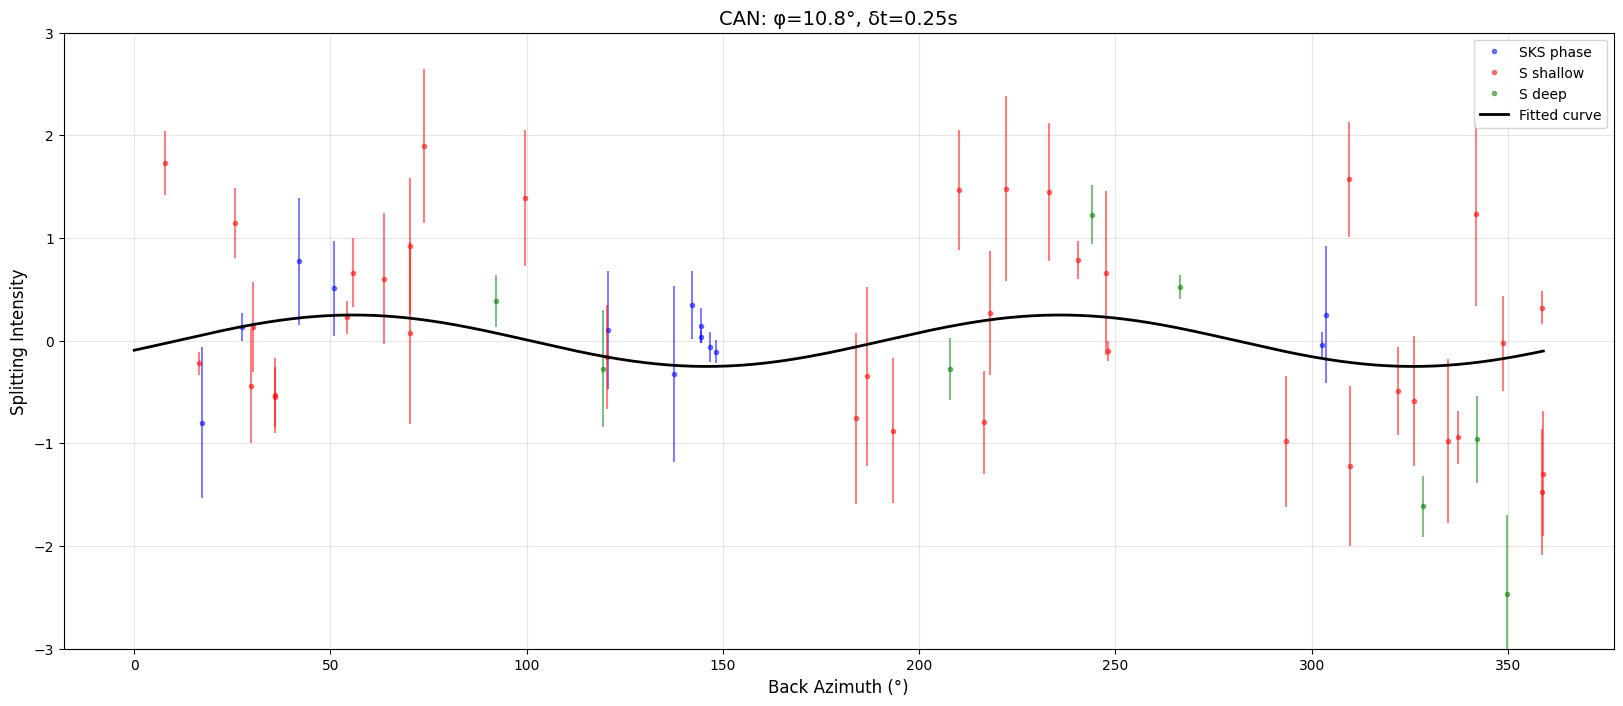

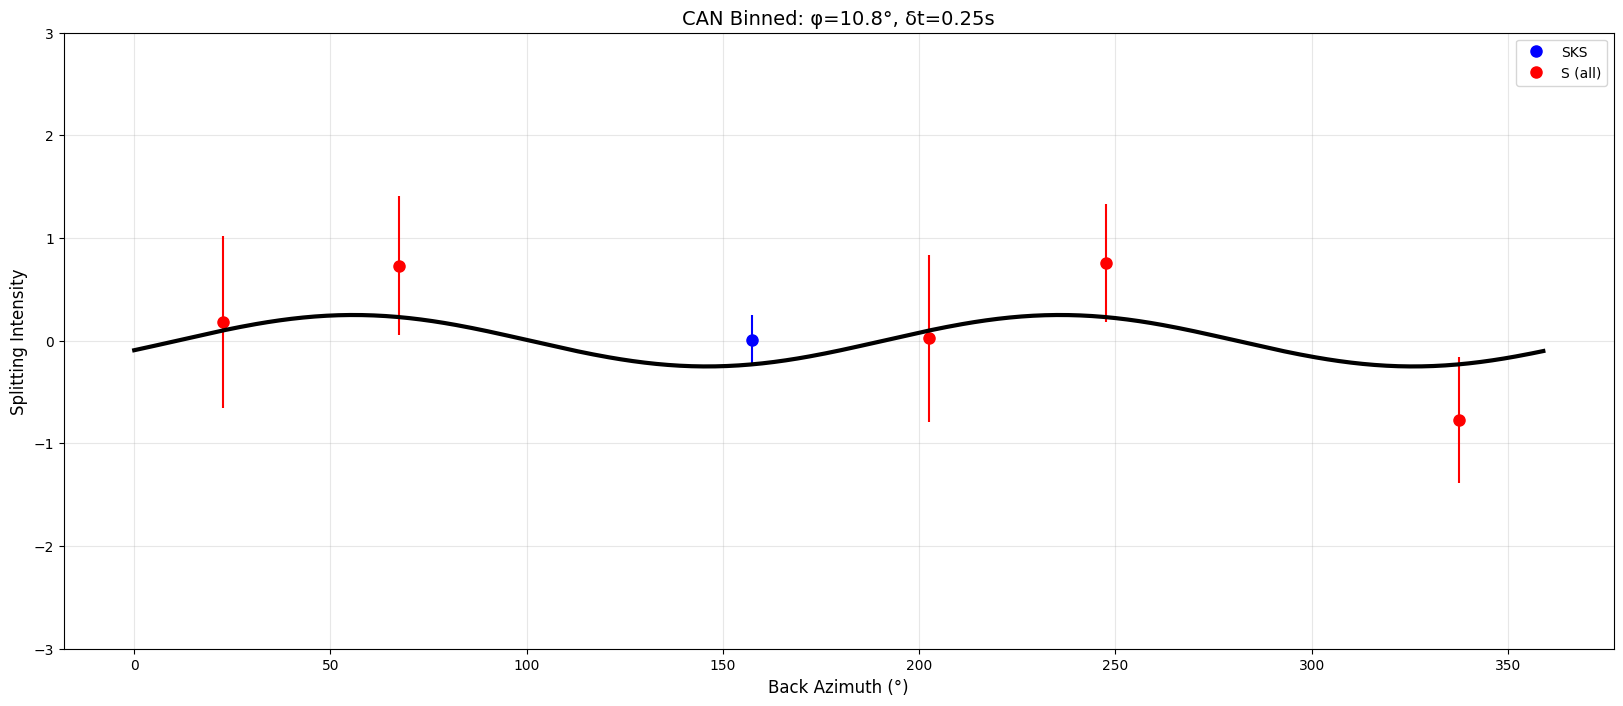

In [15]:
# ==================== Analyze single station ====================
station_code = 'CAN'

result = analysis.analyze_station(
    event_data=eventData,
    station_code=station_code,
    bin_width=45,
    bin_minimum=2,
    s_depth=400,
    weights={'sks': 1, 's': 1, 's_depth': 1, 's_shallow': 1},
    incident_angle=20,
    use_tilt=False
)

if result is not None:
    print(f"\n{station_code} Results:")
    print(f"  φ (fast axis): {result['phi']:.2f}°")
    print(f"  δt (delay time): {result['dt']:.3f} s")
    if 'tilt' in result:
        print(f"  Tilt: {result['tilt']:.2f}°")
    print(f"  N measurements: {result['n_events']}")
    
    # ==================== Plot ====================
    # Individual measurements
    # fig1, ax1 = plotting.plot_si_measurements(result, wolf_data=fullwolf)
    fig1, ax1 = plotting.plot_si_measurements(result, wolf_data=None)

    plt.show()
    
    # Binned measurements
    # fig2, ax2 = plotting.plot_binned_measurements(result, wolf_data=fullwolf)
    fig2, ax2 = plotting.plot_binned_measurements(result, wolf_data=None)

    plt.show()
    
    # Map
    # fig3, ax3 = plotting.plot_station_map(result,s_depth=400)
    plt.show()
    
    # Or: comprehensive plot
    # fig = plotting.plot_full_analysis(result, wolf_data=fullwolf)
    # plt.show()
else:
    print(f"No results for {station_code}")


In [ ]:

station_events = eventData[eventData['evstation'] == 'BBOO']

# Plot SI split by distance
fig, (ax1, ax2) = plotting.plot_si_by_distance_groups(
    station_events,
    distance_threshold=60,
    s_depth=400,
    station_code='BBOO'
)
plt.show()

In [ ]:
# crazy grouping idea fr


# 2. Group stations into 5° x 5° boxes
grouped = analysis.group_stations_by_grid(
    eventData,
    grid_size=25.0,
    min_stations_per_group=3  # at least 2 stations per group
)

# 3. Analyze each group
grouped_results = []

for grid_key, group_data in grouped.items():
    result = analysis.analyze_station_group(
        group_data,
        bin_width=5,
        bin_minimum=2,
        s_depth=400
    )
    if result is not None:
        grouped_results.append(result)
        print(f"Group {grid_key}: φ={result['phi']:.1f}°, δt={result['dt']:.2f}s, "
              f"{result['n_stations']} stations, {result['n_events']} measurements")

# 4. Plot all groups together
fig1, axes = plotting.plot_grouped_si_measurements(grouped_results, s_depth=400)
plt.show()

# 5. Plot map showing group locations and fast directions
fig2, ax = plotting.plot_station_group_map(grouped_results)
plt.show()

In [17]:
eventData.columns

Index(['evtime', 'evlat', 'evlon', 'evdp', 'evmg', 'evphase', 'evnetwork',
       'evstation', 'evstationlat', 'evstationlon', 'waveform_path', 'evdist',
       'evaz', 'evbaz', 'evepic', 'evincident', 'evtakeoff', 'evrayparam',
       'evpiercedepth', 'windowstart', 'windowend', 'calcbaz', 'deltaphi',
       'sta_lta', 'snrbefore', 'snrafter', 'ellipticity', 'freq',
       'delta_travel', 'wiggleSIlow_act', 'wiggleSI_act', 'wiggleSIhigh_act',
       'wiggleSIlow_calc', 'wiggleSI_calc', 'wiggleSIhigh_calc',
       'SI_calc_error'],
      dtype='object')